In [1]:
import pandas as pd

# Load raw ACS micro‑data
acs_df = pd.read_csv("usa_00001.csv")
acs_df.columns = acs_df.columns.str.strip()

# Filter valid wage records: exclude missing flag 999999, keep positive wage
acs_df = acs_df[(acs_df["INCWAGE"] < 999999) & (acs_df["INCWAGE"] > 0)]

# Compute weighted average wage by occupation using PERWT weight
occ_avg_wage = acs_df.groupby("OCC").apply(
    lambda x: pd.Series({
        "occ_mean_wage": (x["INCWAGE"] * x["PERWT"]).sum() / x["PERWT"].sum(),
        "sample_count": len(x)
    })
).reset_index()

# Export Dataset2 (this file needs to be submitted for assignment)
occ_avg_wage.to_csv("acs_2024_occ_avg_wage.csv", index=False)

print(" Dataset 2 generated")
print(f"Number of unique occupations: {occ_avg_wage.shape[0]}")
occ_avg_wage.head()


 Dataset 2 generated
Number of unique occupations: 529


,OCC,occ_mean_wage,sample_count
0,10,207252.508557,18143.0
1,20,102850.973441,13738.0
2,40,102457.301668,606.0
3,51,109997.505493,6604.0
4,52,137008.020018,6049.0


In [2]:
# Load Dataset1: raw CPS‑ASEC individual‑level dataset
cps_df = pd.read_csv("cps_00001.csv")
cps_df.columns = cps_df.columns.str.strip()

# Load the aggregated Dataset2 we just created
occ_avg_wage = pd.read_csv("acs_2024_occ_avg_wage.csv")

# Left merge two datasets using harmonized occupation code "OCC" as key
merged_df = pd.merge(cps_df, occ_avg_wage, on="OCC", how="left")

print(f"Total observations after merge: {merged_df.shape[0]}")
print(f"Observations with missing occ_mean_wage: {merged_df['occ_mean_wage'].isna().sum()}")

# Save intermediate merged file (for self‑analysis, DO NOT submit)
merged_df.to_csv("merged_cps_acs.csv", index=False)
print(" Merged intermediate file saved")


Total observations after merge: 144265
Observations with missing occ_mean_wage: 72613
 Merged intermediate file saved


In [23]:
# Read merged intermediate dataset
df = pd.read_csv("merged_cps_acs.csv")

# Data cleaning rules
# 1. Keep positive wage value, drop INCWAGE missing code 999999
# 2. Drop observations without matched occupational average wage
df = df[(df["INCWAGE"] > 0) & (df["INCWAGE"] < 999999)]
df = df.dropna(subset=["occ_mean_wage"])

print(f"Valid sample size after cleaning: {df.shape[0]}")

print("\n==== Descriptive Statistics ====")
print(df[["AGE", "INCWAGE", "occ_mean_wage"]].describe())


Valid sample size after cleaning: 65302

==== Descriptive Statistics ====
                AGE        INCWAGE  occ_mean_wage
count  65302.000000   65302.000000   65302.000000
mean      42.308827   68153.573091   66535.184086
std       14.292245   69514.748209   41655.427448
min       15.000000       2.000000    7599.696994
25%       31.000000   30000.000000   37794.930467
50%       42.000000   50000.000000   55341.710318
75%       53.000000   85000.000000   86789.341095
max       85.000000  960000.000000  404795.941431


In [24]:
!pip install statsmodels


In [25]:
import statsmodels.api as sm

# Set independent variables: AGE, SEX, EDUC, occ_mean_wage
X = df[["AGE", "SEX", "EDUC", "occ_mean_wage"]]
X = sm.add_constant(X)  # add intercept(constant term) for regression

# Dependent variable: individual wage‑salary income
y = df["INCWAGE"]

# Fit OLS regression model
model = sm.OLS(y, X).fit()  

# Print full regression output table
print(model.summary())


                            OLS Regression Results                            
Dep. Variable:                INCWAGE   R-squared:                       0.319
Model:                            OLS   Adj. R-squared:                  0.319
Method:                 Least Squares   F-statistic:                     7643.
Date:                Wed, 16 Sep 2026   Prob (F-statistic):               0.00
Time:                        16:10:50   Log-Likelihood:            -8.0819e+05
No. Observations:               65302   AIC:                         1.616e+06
Df Residuals:                   65297   BIC:                         1.616e+06
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const         -1.925e+04   1217.884    -15.807

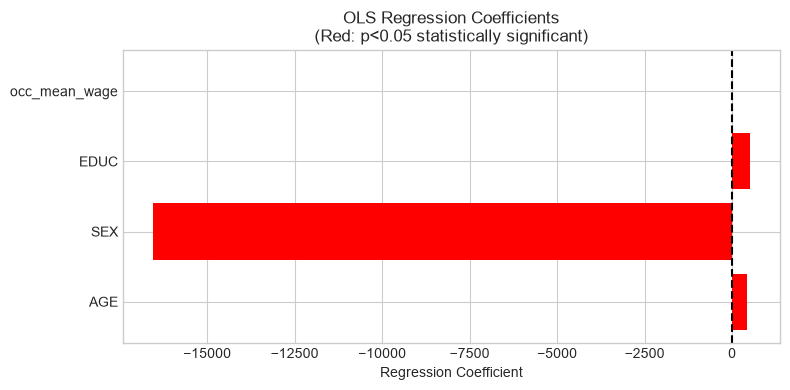

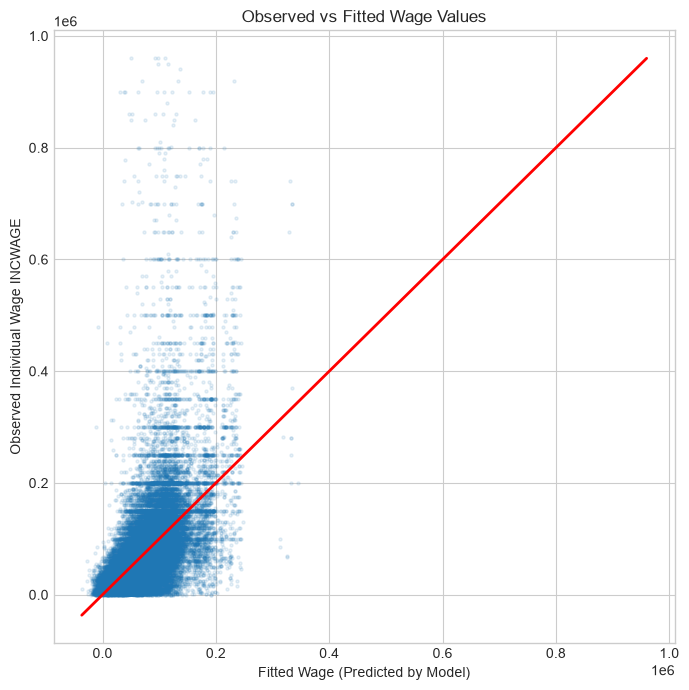

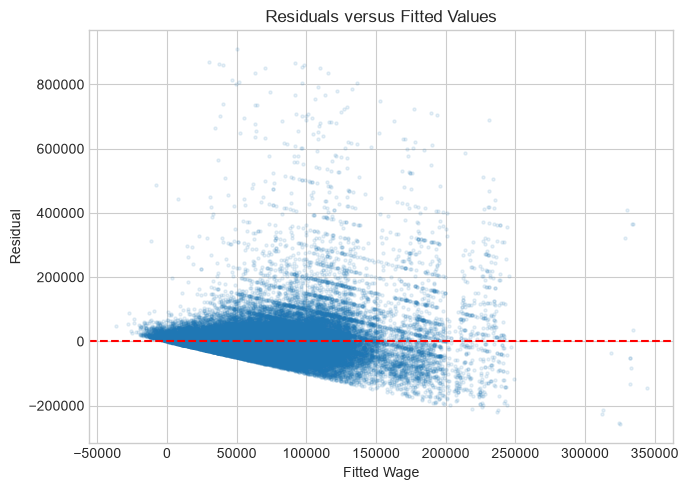

In [26]:
import matplotlib.pyplot as plt
import numpy as np
import statsmodels.api as sm
from statsmodels.graphics.gofplots import qqplot

# set plot style
plt.style.use("seaborn-v0_8-whitegrid")

# ---------------------- 1. Coefficient bar chart 系数条形图（作业首选） ----------------------
# extract coefficient and variable names, drop constant term
coef_df = pd.DataFrame({
    "variable": model.params.index,
    "coefficient": model.params.values,
    "p_value": model.pvalues.values
})
coef_df = coef_df[coef_df["variable"] != "const"]

fig1, ax1 = plt.subplots(figsize=(8, 4))
colors = ["red" if p<0.05 else "gray" for p in coef_df["p_value"]]
ax1.barh(coef_df["variable"], coef_df["coefficient"], color=colors)
ax1.axvline(x=0, color="black", linestyle="--")
ax1.set_xlabel("Regression Coefficient")
ax1.set_title("OLS Regression Coefficients\n(Red: p<0.05 statistically significant)")
plt.tight_layout()
plt.savefig("reg_coef_bar.png", dpi=300)
plt.show()

# ---------------------- 2. Observed vs Fitted 真实工资 vs 预测工资 ----------------------
y_observed = df["INCWAGE"]
y_fitted = model.fittedvalues

fig2, ax2 = plt.subplots(figsize=(7,7))
ax2.scatter(y_fitted, y_observed, alpha=0.1, s=5)
# 45‑degree reference line
min_val = min(y_fitted.min(), y_observed.min())
max_val = max(y_fitted.max(), y_observed.max())
ax2.plot([min_val, max_val], [min_val, max_val], color="red", lw=2)
ax2.set_xlabel("Fitted Wage (Predicted by Model)")
ax2.set_ylabel("Observed Individual Wage INCWAGE")
ax2.set_title("Observed vs Fitted Wage Values")
plt.tight_layout()
plt.savefig("observed_vs_fitted.png", dpi=300)
plt.show()

# ----------------------3. Residual vs Fitted 残差‑拟合值图（异方差检验） ----------------------
residual = model.resid

fig3, ax3 = plt.subplots(figsize=(7,5))
ax3.scatter(y_fitted, residual, alpha=0.1, s=5)
ax3.axhline(y=0, color="red", linestyle="--")
ax3.set_xlabel("Fitted Wage")
ax3.set_ylabel("Residual")
ax3.set_title("Residuals versus Fitted Values")
plt.tight_layout()
plt.savefig("residual_fitted.png", dpi=300)
plt.show()
